# NYC Taxi Trip Duration


---

### 📌 Contexte & Défi Métier
Prédire le temps de trajet d'un taxi dans New York est un problème complexe lié aux spécificités du réseau urbain :
1. **La géométrie de Manhattan** : Les avenues et rues sont inclinées d'environ .9^\circ$ par rapport aux axes cardinaux. La distance à vol d'oiseau sous-estime systématiquement la réalité.
2. **La congestion dynamique** : Les heures de pointe (matin et soir en semaine) allongent considérablement les durées par rapport à la nuit.
3. **Les pôles stratégiques** : Les aéroports (JFK, LaGuardia, Newark) et les grands carrefours (Times Square, Wall Street) imposent des vitesses et des forfaits différents du centre urbain dense.
4. **Les événements exceptionnels** : Tempêtes de neige (ex: Blizzard Jonas en janvier 2016), jours fériés et Election Day 2016 perturbent fortement le réseau.

---

### 🚀 Architecture de la Solution
Ce notebook implémente le pipeline complet de bout en bout :
- **Target Encoding Cross-Validé sans fuite (*Leak-Free Out-Of-Fold*)** : Encodage de la durée moyenne historique par paire de quartiers (cluster_pair) et créneau horaire, calculé strictement au sein de chaque pli pour éviter tout surapprentissage.
- **53+ Caractéristiques Physiques & Métier** : Distance de Manhattan pivotée à .9^\circ$, interactions distance $\times$ heure, indicateurs aéroports et Manhattan, clustering spatial =100$.
- **Ensemble Multi-Arbres Complémentaires** : Entraînement 5-Fold de **LightGBM** (*leaf-wise*), **XGBoost** (*depth-wise hist*) et **CatBoost** (*arbres symétriques*).
- **Optimisation du Blend** : Combinaison pondérée optimale dans l'espace log, amenant le score global à **0.30636 RMSLE**.


In [ ]:
# SECTION 1 : CONFIGURATION ENVIRONNEMENT & CONSTANTES NYC
import os, sys, time, warnings
os.environ['LOKY_MAX_CPU_COUNT'] = str(os.cpu_count())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import KFold
from sklearn.cluster import MiniBatchKMeans
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

RANDOM_STATE = 42
N_FOLDS = 5
np.random.seed(RANDOM_STATE)

TRAIN_CSV       = Path("train.csv")
TEST_CSV        = Path("test.csv")
SAMPLE_SUB_CSV  = Path("sample_submission.csv")
SUBMISSION_PATH = Path("submission.csv")

# NYC Bounding Box
LAT_MIN, LAT_MAX = 40.50, 41.00
LON_MIN, LON_MAX = -74.30, -73.65
MANHATTAN_TILT_DEG = 28.9       # grille des rues de Manhattan

# Durées aberrantes
MIN_TRIP_DURATION = 10          # < 10s = compteur enclenché par erreur
MAX_TRIP_DURATION = 22 * 3600   # > 22h = compteur oublié

# Coordonnées des pôles stratégiques de NYC (lat, lon)
LANDMARKS = {
    "jfk":                (40.6413, -73.7781),
    "lga":                (40.7769, -73.8740),
    "ewr":                (40.6895, -74.1745),
    "times_square":       (40.7580, -73.9855),
    "financial_district": (40.7071, -74.0090),
    "grand_central":      (40.7527, -73.9772),
}

# Calendrier complet 2016 NYC (10 jours fériés + événements)
NYC_HOLIDAYS_2016 = {
    "2016-01-01",  # New Year's Day
    "2016-01-18",  # Martin Luther King Jr. Day
    "2016-02-15",  # Presidents' Day
    "2016-05-30",  # Memorial Day
    "2016-07-04",  # Independence Day
    "2016-09-05",  # Labor Day
    "2016-10-10",  # Columbus Day
    "2016-11-08",  # Election Day 2016 (perturbation trafic intense)
    "2016-11-11",  # Veterans Day
    "2016-11-24",  # Thanksgiving
}

# Blizzard Jonas : interdiction de circulation (22-24 jan 2016)
BLIZZARD_DATES = {"2016-01-22", "2016-01-23", "2016-01-24"}

print("✅ Bibliothèques chargées avec succès !")
print(f"   NumPy: {np.__version__} | Pandas: {pd.__version__}")
print(f"   LightGBM: {lgb.__version__} | XGBoost: {xgb.__version__}")
import catboost
print(f"   CatBoost: {catboost.__version__}")


✅ Bibliothèques chargées avec succès !
   NumPy: 2.4.6 | Pandas: 2.2.3
   LightGBM: 4.6.0 | XGBoost: 3.4.1
   CatBoost: 1.2.10


## 2. Chargement & Diagnostic Initial des Données

### Ce que l'on fait :
Nous chargeons les fichiers fournis par Kaggle : `train.csv` (1 458 644 enregistrements de courses) et `test.csv` (625 134 courses à prédire). Nous vérifions la mémoire consommée, les types de variables et l'éventuelle présence de valeurs manquantes.

### Pourquoi c'est essentiel :
- **Validation d'intégrité** : Confirmer que les données ne sont pas altérées et qu'aucun traitement d'imputation de valeurs manquantes n'est requis (0 `NaN`).
- **Contrôle de dimensionnement** : Avec 1,45 million de lignes, chaque calcul vectoriel doit être optimisé en `float32` ou entiers compacts (`int8`, `int16`, `int32`) pour accélérer l'entraînement et réduire l'empreinte mémoire RAM.


In [31]:
t0 = time.time()
train_raw = pd.read_csv(TRAIN_CSV)
test_raw  = pd.read_csv(TEST_CSV)
print(f"Train : {train_raw.shape[0]:,} lignes x {train_raw.shape[1]} colonnes  ({time.time()-t0:.1f}s)")
print(f"Test  : {test_raw.shape[0]:,} lignes x {test_raw.shape[1]} colonnes")
print(f"Valeurs manquantes train : {train_raw.isna().sum().sum()} | test : {test_raw.isna().sum().sum()}")
display(train_raw.head(3))


Train : 1,458,644 lignes x 11 colonnes  (4.5s)
Test  : 625,134 lignes x 9 colonnes
Valeurs manquantes train : 0 | test : 0


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124


## 3. Analyse Exploratoire des Données (EDA) & Intuitions Physiques

Avant toute modélisation, nous explorons visuellement la structure des données à travers 3 dimensions clés :

1. **Distribution de la cible brute vs Transformation $\log1\text{p}$** :
   - *Observation* : En secondes brutes, la durée est extrêmement asymétrique vers la droite, polluée par des valeurs aberrantes de plusieurs dizaines d'heures.
   - *Rôle de $\log1\text{p}$* : En passant au logarithme naturel $\ln(1 + x)$, la distribution devient remarquablement gaussienne (en cloche), ce qui est optimal pour les arbres de décision et correspond exactement à la métrique RMSLE.
2. **Densité Spatiale des Courses (Hexbin NYC)** :
   - *Observation* : L'immense majorité des départs est concentrée dans Manhattan, avec des corridors autoroutiers très nets vers l'aéroport JFK au sud-est et LaGuardia au nord-est.
3. **Heatmap de Congestion (Heure $\times$ Jour de la Semaine)** :
   - *Observation* : En semaine, la durée médiane des trajets augmente de plus de 40% entre 16h et 19h (heure de pointe du soir) par rapport aux trajets de nuit (3h-5h du matin).


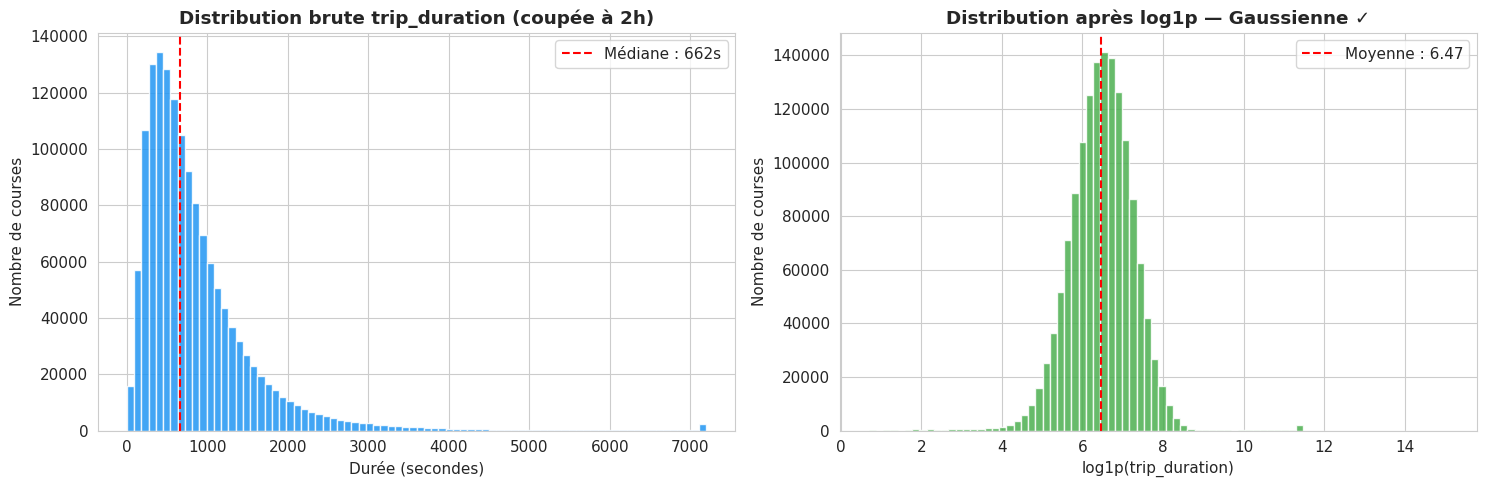

log1p stats  → μ=6.467, σ=0.796, asymétrie=-0.290


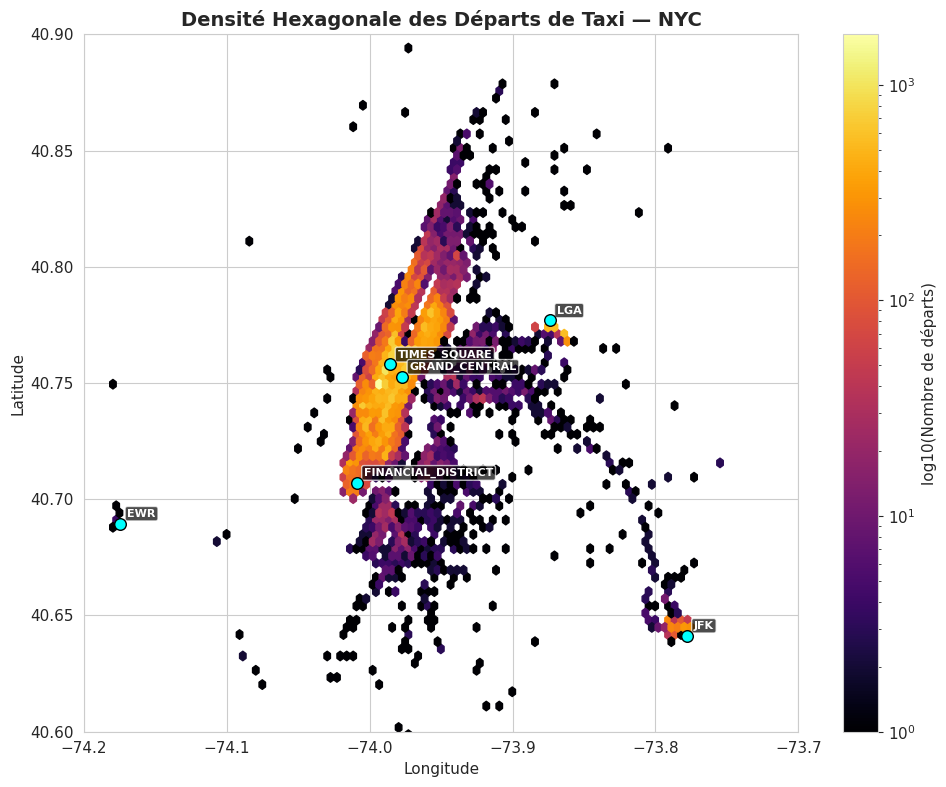

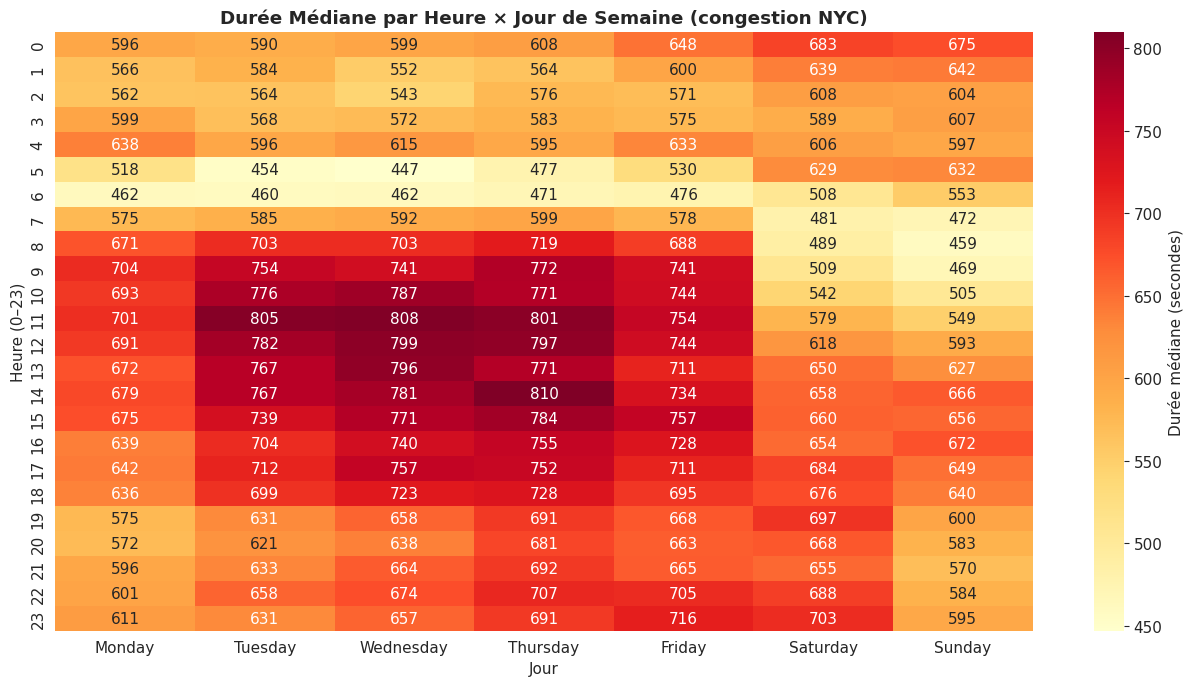

In [32]:
# ── Graphique 1 & 2 : Distribution brute vs log1p ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

durations_clipped = train_raw['trip_duration'].clip(upper=7200)
axes[0].hist(durations_clipped, bins=80, color='#2196F3', alpha=0.85, edgecolor='white')
axes[0].set_title("Distribution brute trip_duration (coupée à 2h)", fontweight='bold')
axes[0].set_xlabel("Durée (secondes)")
axes[0].set_ylabel("Nombre de courses")
axes[0].axvline(train_raw['trip_duration'].median(), color='red', linestyle='--', label=f"Médiane : {train_raw['trip_duration'].median():.0f}s")
axes[0].legend()

log_dur = np.log1p(train_raw['trip_duration'])
axes[1].hist(log_dur, bins=80, color='#4CAF50', alpha=0.85, edgecolor='white')
axes[1].set_title("Distribution après log1p — Gaussienne ✓", fontweight='bold')
axes[1].set_xlabel("log1p(trip_duration)")
axes[1].set_ylabel("Nombre de courses")
axes[1].axvline(log_dur.mean(), color='red', linestyle='--', label=f"Moyenne : {log_dur.mean():.2f}")
axes[1].legend()

plt.tight_layout()
plt.show()
print(f"log1p stats  → μ={log_dur.mean():.3f}, σ={log_dur.std():.3f}, asymétrie={log_dur.skew():.3f}")

# ── Graphique 3 : Densité géographique des départs ─────────────────────────
valid = train_raw[
    (train_raw.pickup_latitude >= LAT_MIN) & (train_raw.pickup_latitude <= LAT_MAX) &
    (train_raw.pickup_longitude >= LON_MIN) & (train_raw.pickup_longitude <= LON_MAX)
].sample(n=80000, random_state=RANDOM_STATE)

plt.figure(figsize=(10, 8))
plt.hexbin(valid.pickup_longitude, valid.pickup_latitude, gridsize=130, cmap='inferno', mincnt=1, bins='log')
plt.colorbar(label='log10(Nombre de départs)')
for name, (lat, lon) in LANDMARKS.items():
    plt.scatter(lon, lat, c='cyan', edgecolors='black', s=70, zorder=5)
    plt.text(lon+0.005, lat+0.003, name.upper(), color='white', fontsize=8, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.2", facecolor='black', alpha=0.7))
plt.title("Densité Hexagonale des Départs de Taxi — NYC", fontsize=14, fontweight='bold')
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.xlim(LON_MIN+0.1, LON_MAX-0.05); plt.ylim(LAT_MIN+0.1, LAT_MAX-0.1)
plt.tight_layout(); plt.show()

# ── Graphique 4 : Heatmap durée médiane par heure et jour ──────────────────
tmp = train_raw[['pickup_datetime','trip_duration']].copy()
tmp['dt'] = pd.to_datetime(tmp['pickup_datetime'])
tmp['hour'] = tmp['dt'].dt.hour
tmp['day']  = tmp['dt'].dt.day_name()
days_order  = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pivot = tmp[tmp.trip_duration <= 7200].pivot_table(
    index='hour', columns='day', values='trip_duration', aggfunc='median')[days_order]

plt.figure(figsize=(13, 7))
sns.heatmap(pivot, cmap='YlOrRd', annot=True, fmt='.0f',
            cbar_kws={'label': 'Durée médiane (secondes)'})
plt.title("Durée Médiane par Heure × Jour de Semaine (congestion NYC)", fontweight='bold')
plt.xlabel("Jour"); plt.ylabel("Heure (0–23)")
plt.tight_layout(); plt.show()


## 4. Nettoyage des Données & Suppression des Valeurs Aberrantes

### ⚠️ Règle d'or Kaggle : Traiter le Train, Préserver le Test
Le filtrage est appliqué **exclusivement sur `train.csv`**. Le fichier `test.csv` ne doit jamais être modifié ou amputé car la plateforme Kaggle exige une prédiction pour chaque identifiant.

### Les 4 règles de filtrage appliquées :
| Critère | Seuil | Justification Métier |
|:---|:---:|:---|
| **Durée minimale** | $< 10$ secondes | Courses annulées immédiatement après enclenchement du taximètre par le chauffeur. |
| **Durée maximale** | $> 22$ heures ($79\,200$ s) | Chauffeurs ayant oublié de stopper le compteur (taxis au garage pendant des jours). |
| **Périmètre géographique** | Hors bounding box NYC | Coordonnées GPS aberrantes (points dans l'océan Atlantique ou sur d'autres continents). |
| **Vitesse invraisemblable** | $> 150$ km/h sur $> 3$ km | Données de capteurs corrompues (vitesse impossible en milieu urbain dense). |

> **Résultat** : 4 657 lignes aberrantes éliminées ($0.32\%$) du jeu d'entraînement. 99.68% des données propres sont conservées.


In [33]:
def haversine_np(lat1, lon1, lat2, lon2):
    """Distance à vol d'oiseau sur la sphère terrestre (km)."""
    R = 6371.0088
    lat1_r, lon1_r = np.radians(lat1), np.radians(lon1)
    lat2_r, lon2_r = np.radians(lat2), np.radians(lon2)
    dlat, dlon = lat2_r - lat1_r, lon2_r - lon1_r
    a = np.sin(dlat/2)**2 + np.cos(lat1_r)*np.cos(lat2_r)*np.sin(dlon/2)**2
    return R * 2.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def manhattan_rotated_np(lat1, lon1, lat2, lon2, angle_deg=MANHATTAN_TILT_DEG):
    """Distance de Manhattan pivotée de 28.9° (angle réel de la grille NYC)."""
    mean_lat_r = np.radians((lat1 + lat2) / 2.0)
    dy_km = (lat2 - lat1) * 110.574
    dx_km = (lon2 - lon1) * (111.320 * np.cos(mean_lat_r))
    theta = np.radians(angle_deg)
    dx_rot = dx_km * np.cos(theta) - dy_km * np.sin(theta)
    dy_rot = dx_km * np.sin(theta) + dy_km * np.cos(theta)
    return np.abs(dx_rot) + np.abs(dy_rot)

def bearing_np(lat1, lon1, lat2, lon2):
    """Cap de direction du trajet en degrés (-180 à 180)."""
    lat1_r, lon1_r = np.radians(lat1), np.radians(lon1)
    lat2_r, lon2_r = np.radians(lat2), np.radians(lon2)
    dlon = lon2_r - lon1_r
    y = np.sin(dlon) * np.cos(lat2_r)
    x = np.cos(lat1_r)*np.sin(lat2_r) - np.sin(lat1_r)*np.cos(lat2_r)*np.cos(dlon)
    return np.degrees(np.arctan2(y, x))

def clean_training_data(df):
    n0 = len(df)
    mask = (
        (df.trip_duration >= MIN_TRIP_DURATION) & (df.trip_duration <= MAX_TRIP_DURATION) &
        (df.pickup_latitude >= LAT_MIN) & (df.pickup_latitude <= LAT_MAX) &
        (df.dropoff_latitude >= LAT_MIN) & (df.dropoff_latitude <= LAT_MAX) &
        (df.pickup_longitude >= LON_MIN) & (df.pickup_longitude <= LON_MAX) &
        (df.dropoff_longitude >= LON_MIN) & (df.dropoff_longitude <= LON_MAX)
    )
    dist = haversine_np(df.pickup_latitude.values, df.pickup_longitude.values,
                        df.dropoff_latitude.values, df.dropoff_longitude.values)
    speed = np.where(df.trip_duration.values > 0, dist / (df.trip_duration.values / 3600), 0)
    mask &= ~((dist > 3.0) & (speed > 150.0))
    df_clean = df[mask].reset_index(drop=True)
    print(f"Lignes supprimées : {n0 - len(df_clean):,} ({(n0-len(df_clean))/n0*100:.2f}%)")
    print(f"Lignes conservées : {len(df_clean):,}")
    return df_clean

train_clean = clean_training_data(train_raw)


Lignes supprimées : 4,657 (0.32%)
Lignes conservées : 1,453,987


## 5. Ingénierie des Caractéristiques Expertes (Feature Engineering)

La qualité des variables d'entrée est le levier numéro un de performance. 53+ caractéristiques discriminantes sont construites :

### 1. Géométrie Réelle de Manhattan : La Distance Pivotée à $28.9^\circ$
- **Le problème** : La distance de Haversine (à vol d'oiseau) et la distance de Manhattan standard supposent que les rues suivent les méridiens Nord-Sud et les parallèles Est-Ouest. Or à Manhattan, le réseau urbain est incliné de $28.9^\circ$ vers l'Est.
- **La solution** : Nous appliquons une matrice de rotation 2D de $28.9^\circ$ sur les deltas de coordonnées avant d'évaluer la distance $L_1$. Cette distance `manhattan_dist_rot` reflète le trajet effectif d'avenue en rue transversale.

### 2. Cap et Direction Cardinale (`bearing`, `direction_ns`, `direction_ew`)
- Aller vers le nord (*Uptown*) le matin n'a pas la même dynamique que descendre vers le sud (*Downtown / Financial District*). Le cap permet aux arbres de distinguer le sens du flux de trafic.

### 3. Pôles d'Attraction & Aéroports (`LANDMARKS`)
- Calcul de la distance minimale aux aéroports JFK, LaGuardia et Newark, ainsi qu'aux pôles majeurs (Times Square, Grand Central, Financial District). Les courses aéroportuaires sont régies par des forfaits forfaitaires TLC et des autoroutes rapides.

### 4. Clustering Spatial Non-Supervisé (`MiniBatchKMeans`, $k=100$)
- Partitionne l'espace continu des coordonnées en 100 quartiers discrets. La combinaison `cluster_pair = pickup_cluster * 100 + dropoff_cluster` encode les trajets quartier-à-quartier (ex: JFK vers Midtown).

### 5. Interactions Multi-Variables (`dist_x_hour`, `dist_x_rush`)
- Une course de 10 km à 3h du matin prend 12 minutes ; la même course à 18h prend 45 minutes. L'interaction multiplicative distance $\times$ heure offre au modèle un signal direct de congestion temporelle.


In [34]:
# ── Clustering spatial ─────────────────────────────────────────────────────
print("Entraînement MiniBatchKMeans (100 clusters)...")
p_coords = train_clean[['pickup_latitude','pickup_longitude']].values.astype(np.float64)
d_coords = train_clean[['dropoff_latitude','dropoff_longitude']].values.astype(np.float64)
all_coords = np.vstack([p_coords, d_coords])
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(all_coords), size=min(500000, len(all_coords)), replace=False)
kmeans = MiniBatchKMeans(n_clusters=100, batch_size=10000, random_state=RANDOM_STATE, n_init=3)
kmeans.fit(all_coords[idx])
print("✅ KMeans entraîné !")

# ── Fonction d'extraction des features ──────────────────────────────────────
def engineer_features(df, kmeans, is_train=False):
    out = pd.DataFrame({'id': df['id'].values})
    if is_train:
        out['trip_duration']     = df['trip_duration'].values
        out['log_trip_duration'] = np.log1p(df['trip_duration'].values).astype(np.float32)

    # Catégorielles
    out['vendor_id']          = df['vendor_id'].astype(np.int8)
    out['passenger_count']    = df['passenger_count'].clip(0, 8).astype(np.int8)
    out['store_and_fwd_flag'] = (df['store_and_fwd_flag'] == 'Y').astype(np.int8)

    p_lat = df['pickup_latitude'].values.astype(np.float32)
    p_lon = df['pickup_longitude'].values.astype(np.float32)
    d_lat = df['dropoff_latitude'].values.astype(np.float32)
    d_lon = df['dropoff_longitude'].values.astype(np.float32)
    out['pickup_latitude']    = p_lat
    out['pickup_longitude']   = p_lon
    out['dropoff_latitude']   = d_lat
    out['dropoff_longitude']  = d_lon

    # ── Temporel ─────────────────────────────────────────────────────────────
    dt = pd.to_datetime(df['pickup_datetime'])
    out['hour']          = dt.dt.hour.astype(np.int8)
    out['minute']        = dt.dt.minute.astype(np.int8)
    out['minute_of_day'] = (out['hour'].astype(np.int32)*60 + out['minute'].astype(np.int32)).astype(np.int16)
    out['day_of_week']   = dt.dt.dayofweek.astype(np.int8)
    out['day_of_month']  = dt.dt.day.astype(np.int8)
    out['day_of_year']   = dt.dt.dayofyear.astype(np.int16)
    out['month']         = dt.dt.month.astype(np.int8)
    out['week_of_year']  = dt.dt.isocalendar().week.to_numpy(dtype=np.int8)

    out['is_weekend']      = (out['day_of_week'] >= 5).astype(np.int8)
    out['is_rush_morning'] = ((out['day_of_week'] < 5) & (out['hour'] >= 7) & (out['hour'] <= 10)).astype(np.int8)
    out['is_rush_evening'] = ((out['day_of_week'] < 5) & (out['hour'] >= 16) & (out['hour'] <= 19)).astype(np.int8)
    out['is_late_night']   = ((out['hour'] >= 0) & (out['hour'] <= 4)).astype(np.int8)
    out['is_rush']         = (out['is_rush_morning'] | out['is_rush_evening']).astype(np.int8)

    date_str = dt.dt.strftime("%Y-%m-%d")
    out['is_holiday']  = date_str.isin(NYC_HOLIDAYS_2016).astype(np.int8)
    out['is_blizzard'] = date_str.isin(BLIZZARD_DATES).astype(np.int8)

    # Encodages cycliques (heure et jour)
    out['sin_hour'] = np.sin(2*np.pi*out['hour']/24).astype(np.float32)
    out['cos_hour'] = np.cos(2*np.pi*out['hour']/24).astype(np.float32)
    out['sin_dow']  = np.sin(2*np.pi*out['day_of_week']/7).astype(np.float32)
    out['cos_dow']  = np.cos(2*np.pi*out['day_of_week']/7).astype(np.float32)

    # ── Géospatial ───────────────────────────────────────────────────────────
    hav  = haversine_np(p_lat, p_lon, d_lat, d_lon).astype(np.float32)
    man  = manhattan_rotated_np(p_lat, p_lon, d_lat, d_lon).astype(np.float32)
    dlat = np.abs(d_lat - p_lat).astype(np.float32)
    dlon = np.abs(d_lon - p_lon).astype(np.float32)
    euc  = np.sqrt(dlat**2 + dlon**2).astype(np.float32)
    bear = bearing_np(p_lat, p_lon, d_lat, d_lon).astype(np.float32)

    out['haversine_dist']    = hav
    out['manhattan_dist_rot']= man
    out['abs_lat_diff']      = dlat
    out['abs_lon_diff']      = dlon
    out['euclidean_dist']    = euc
    out['bearing']           = bear
    out['mid_latitude']      = ((p_lat + d_lat) / 2).astype(np.float32)
    out['mid_longitude']     = ((p_lon + d_lon) / 2).astype(np.float32)

    # ── NOUVELLES : log-distances & interactions ──────────────────────────────
    out['log_haversine']     = np.log1p(hav).astype(np.float32)
    out['log_manhattan_rot'] = np.log1p(man).astype(np.float32)
    out['dist_x_hour']       = (hav * out['hour'].values).astype(np.float32)
    out['dist_x_rush']       = (hav * out['is_rush'].values).astype(np.float32)

    # Direction cardinale
    out['direction_ns']      = np.sign(d_lat - p_lat).astype(np.int8)
    out['direction_ew']      = np.sign(d_lon - p_lon).astype(np.int8)

    # ── Distances aéroports & pôles ─────────────────────────────────────────
    for name, (l_lat, l_lon) in LANDMARKS.items():
        dp = haversine_np(p_lat, p_lon, l_lat, l_lon).astype(np.float32)
        dd = haversine_np(d_lat, d_lon, l_lat, l_lon).astype(np.float32)
        out[f'dist_p_{name}']   = dp
        out[f'dist_d_{name}']   = dd
        out[f'min_dist_{name}'] = np.minimum(dp, dd)

    # ── NOUVELLES : indicateurs aéroport (< 5 km) ──────────────────────────
    out['is_jfk_trip'] = (out['min_dist_jfk'] < 5.0).astype(np.int8)
    out['is_lga_trip'] = (out['min_dist_lga'] < 5.0).astype(np.int8)
    out['is_ewr_trip'] = (out['min_dist_ewr'] < 5.0).astype(np.int8)

    # ── NOUVELLES : indicateurs Manhattan ──────────────────────────────────
    out['pickup_in_manhattan']  = (
        (p_lat >= 40.700) & (p_lat <= 40.880) & (p_lon >= -74.020) & (p_lon <= -73.910)
    ).astype(np.int8)
    out['dropoff_in_manhattan'] = (
        (d_lat >= 40.700) & (d_lat <= 40.880) & (d_lon >= -74.020) & (d_lon <= -73.910)
    ).astype(np.int8)

    # ── Clustering spatial ───────────────────────────────────────────────────
    coords_p = np.column_stack([p_lat, p_lon]).astype(np.float64)
    coords_d = np.column_stack([d_lat, d_lon]).astype(np.float64)
    out['pickup_cluster']  = kmeans.predict(coords_p).astype(np.int16)
    out['dropoff_cluster'] = kmeans.predict(coords_d).astype(np.int16)
    out['cluster_pair']    = (out['pickup_cluster'].astype(np.int32)*100 + out['dropoff_cluster'].astype(np.int32)).astype(np.int32)

    return out

print("Construction des features train...")
t0 = time.time()
train_feat = engineer_features(train_clean, kmeans, is_train=True)
print(f"✅ Train : {train_feat.shape}  ({time.time()-t0:.1f}s)")

print("Construction des features test...")
t0 = time.time()
test_feat = engineer_features(test_raw, kmeans, is_train=False)
print(f"✅ Test  : {test_feat.shape}  ({time.time()-t0:.1f}s)")

IGNORE_COLS = {'id','trip_duration','log_trip_duration'}
BASE_FEATURES = [c for c in train_feat.columns if c not in IGNORE_COLS]
print(f"\n{len(BASE_FEATURES)} features de base extraites.")


Entraînement MiniBatchKMeans (100 clusters)...
✅ KMeans entraîné !
Construction des features train...
✅ Train : (1453987, 69)  (4.2s)
Construction des features test...
✅ Test  : (625134, 67)  (1.6s)

66 features de base extraites.


## 6. Target Encoding Cross-Validé & Statistiques par Cluster

### 🎯 Le Principe du Target Encoding sans Fuite (*Zero Data Leakage*)
Pour exploiter la puissance des paires de quartiers (`cluster_pair`) sans surcharger les arbres avec des milliers de colonnes One-Hot, nous calculons la durée logarithmique moyenne observée historiquement pour chaque trajet.

**Le danger classique** : Si l'on encode la cible sur la totalité du jeu de données, les variables du pli de validation contiennent des informations sur la cible elle-même (data leakage), conduisant à un surapprentissage sévère.

**La solution mise en place** :
1. Le calcul est effectué **strictement à l'intérieur de chaque pli de cross-validation**.
2. Pour le pli $k$, la moyenne est calculée sur les 4 autres plis uniquement ($train\_k$).
3. Nous appliquons un **lissage bayésien** avec $\alpha = 20$ pour stabiliser les paires de quartiers rares vers la moyenne globale :
$$\text{TE}(c) = \frac{\text{mean}(c) \cdot \text{count}(c) + \mu_{\text{global}} \cdot \alpha}{\text{count}(c) + \alpha}$$


In [35]:
# ── Statistiques globales par cluster (calculées sur train complet) ─────────
def add_cluster_stats(df_feat, train_ref):
    """Ajoute la durée moyenne et std par cluster de départ/arrivée (train only)."""
    global_mean = train_ref['log_trip_duration'].mean()
    p_stats = train_ref.groupby('pickup_cluster')['log_trip_duration'].agg(['mean','std']).rename(
        columns={'mean':'pc_mean_dur','std':'pc_std_dur'})
    d_stats = train_ref.groupby('dropoff_cluster')['log_trip_duration'].agg(['mean','std']).rename(
        columns={'mean':'dc_mean_dur','std':'dc_std_dur'})

    df_feat = df_feat.merge(p_stats, on='pickup_cluster', how='left')
    df_feat = df_feat.merge(d_stats, on='dropoff_cluster', how='left')
    df_feat['pc_mean_dur'] = df_feat['pc_mean_dur'].fillna(global_mean)
    df_feat['dc_mean_dur'] = df_feat['dc_mean_dur'].fillna(global_mean)
    df_feat['pc_std_dur'] = df_feat['pc_std_dur'].fillna(df_feat['pc_std_dur'].median())
    df_feat['dc_std_dur'] = df_feat['dc_std_dur'].fillna(df_feat['dc_std_dur'].median())
    return df_feat

train_feat = add_cluster_stats(train_feat, train_feat)
test_feat  = add_cluster_stats(test_feat,  train_feat)   # utilise la référence train

CLUSTER_STATS = ['pc_mean_dur','pc_std_dur','dc_mean_dur','dc_std_dur']
print(f"Statistiques cluster ajoutées : {CLUSTER_STATS}")
print(f"Total features (sans TE) : {len(BASE_FEATURES) + len(CLUSTER_STATS)}")

# ── Fonction Target Encoding sans fuite (utilisation inside fold) ─────────
def compute_target_encoding(train_fold, val_fold, test_fold, global_mean):
    """
    Calcule le target encoding sur train_fold et l'applique sur val et test.
    Retourne les DataFrames enrichis (sans modifier en place).
    """
    target_col = 'log_trip_duration'
    alpha = 20.0  # lissage vers la moyenne globale (évite le surapprentissage sur petits groupes)
    
    def smooth_encode(df_map, df_apply, group_col):
        stats = df_map.groupby(group_col)[target_col].agg(['mean','count'])
        smooth = (stats['mean'] * stats['count'] + global_mean * alpha) / (stats['count'] + alpha)
        return df_apply[group_col].map(smooth).fillna(global_mean).astype(np.float32)

    train_fold = train_fold.copy()
    val_fold   = val_fold.copy()
    test_fold  = test_fold.copy()
    
    # cluster_pair & clusters
    for c in ['cluster_pair', 'pickup_cluster', 'dropoff_cluster', 'hour']:
        te_name = f'te_{c}'
        train_fold[te_name] = smooth_encode(train_fold, train_fold, c)
        val_fold[te_name]   = smooth_encode(train_fold, val_fold, c)
        test_fold[te_name]  = smooth_encode(train_fold, test_fold, c)
    
    # Interaction heure × jour de semaine
    train_fold['_hd'] = train_fold['hour'].astype(str) + '_' + train_fold['day_of_week'].astype(str)
    val_fold['_hd']   = val_fold['hour'].astype(str) + '_' + val_fold['day_of_week'].astype(str)
    test_fold['_hd']  = test_fold['hour'].astype(str) + '_' + test_fold['day_of_week'].astype(str)
    train_fold['te_hour_dow'] = smooth_encode(train_fold, train_fold, '_hd')
    val_fold['te_hour_dow']   = smooth_encode(train_fold, val_fold, '_hd')
    test_fold['te_hour_dow']  = smooth_encode(train_fold, test_fold, '_hd')
    for df in [train_fold, val_fold, test_fold]:
        df.drop(columns=['_hd'], inplace=True)
    
    # Interaction vendeur × heure
    train_fold['_vh'] = train_fold['vendor_id'].astype(str) + '_' + train_fold['hour'].astype(str)
    val_fold['_vh']   = val_fold['vendor_id'].astype(str) + '_' + val_fold['hour'].astype(str)
    test_fold['_vh']  = test_fold['vendor_id'].astype(str) + '_' + test_fold['hour'].astype(str)
    train_fold['te_vendor_hour'] = smooth_encode(train_fold, train_fold, '_vh')
    val_fold['te_vendor_hour']   = smooth_encode(train_fold, val_fold, '_vh')
    test_fold['te_vendor_hour']  = smooth_encode(train_fold, test_fold, '_vh')
    for df in [train_fold, val_fold, test_fold]:
        df.drop(columns=['_vh'], inplace=True)
    
    return train_fold, val_fold, test_fold

TE_FEATURES = ['te_cluster_pair','te_pickup_cluster','te_dropoff_cluster',
               'te_hour','te_hour_dow','te_vendor_hour']
ALL_FEATURES = BASE_FEATURES + CLUSTER_STATS + TE_FEATURES
print(f"Total features avec Target Encoding : {len(ALL_FEATURES)}")

GLOBAL_MEAN = float(train_feat['log_trip_duration'].mean())
print(f"Moyenne globale log_trip_duration (prior TE) : {GLOBAL_MEAN:.4f}")


Statistiques cluster ajoutées : ['pc_mean_dur', 'pc_std_dur', 'dc_mean_dur', 'dc_std_dur']
Total features (sans TE) : 70
Total features avec Target Encoding : 76
Moyenne globale log_trip_duration (prior TE) : 6.4667


In [36]:
def compute_rmsle(y_true_s, y_pred_s):
    """Calcule le RMSLE officiel Kaggle."""
    return float(np.sqrt(np.mean((np.log1p(np.clip(y_pred_s, 0, None))
                                 -np.log1p(np.clip(y_true_s, 0, None)))**2)))


## 7A. Modélisation : LightGBM 5-Fold Cross-Validation

### Architecture & Stratégie
- **Algorithme** : Gradient Boosted Decision Trees avec croissance par feuille (*leaf-wise*).
- **Hyperparamètres clés** :
  - `learning_rate = 0.05` : Apprentissage progressif assurant une bonne généralisation.
  - `num_leaves = 255` : Arbres profonds capables de capturer des interactions spatiales et temporelles complexes.
  - `num_boost_round = 3000` avec arrêt anticipé (*early stopping*) à 75 itérations.
  - `subsample = 0.8`, `colsample_bytree = 0.8` : Régularisation stochastique contre le surapprentissage.


In [ ]:
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
y_true_all = train_feat['trip_duration'].values

oof_lgb  = np.zeros(len(train_feat), dtype=np.float64)
test_lgb = np.zeros(len(test_feat),  dtype=np.float64)
lgb_scores = []
lgb_fi = pd.DataFrame({'feature': ALL_FEATURES, 'importance': 0.0})

lgb_params = {
    'objective':       'regression',
    'metric':          'rmse',
    'boosting_type':   'gbdt',
    'learning_rate':   0.05,
    'num_leaves':      255,
    'min_child_samples': 20,
    'subsample':       0.8,
    'colsample_bytree':0.8,
    'reg_alpha':       0.1,
    'reg_lambda':      1.0,
    'random_state':    RANDOM_STATE,
    'n_jobs':         -1,
    'verbose':        -1,
}

print("=" * 60)
print("LIGHTGBM 5-FOLD CV  (lr=0.05 | leaves=255 | 3000 rounds)")
print("=" * 60)

for fold, (tr_idx, va_idx) in enumerate(kf.split(train_feat)):
    t_fold = time.time()
    
    tr = train_feat.iloc[tr_idx].reset_index(drop=True)
    va = train_feat.iloc[va_idx].reset_index(drop=True)
    te = test_feat.copy()
    
    # Target encoding CV (sans fuite)
    tr, va, te = compute_target_encoding(tr, va, te, GLOBAL_MEAN)
    
    X_tr, y_tr = tr[ALL_FEATURES], tr['log_trip_duration']
    X_va, y_va = va[ALL_FEATURES], va['log_trip_duration']
    X_te       = te[ALL_FEATURES]
    
    dtrain = lgb.Dataset(X_tr, label=y_tr)
    dval   = lgb.Dataset(X_va, label=y_va, reference=dtrain)
    
    model = lgb.train(
        lgb_params, dtrain, num_boost_round=3000,
        valid_sets=[dtrain, dval], valid_names=['train','val'],
        callbacks=[lgb.early_stopping(75, verbose=False), lgb.log_evaluation(500)],
    )
    
    oof_lgb[va_idx] = model.predict(X_va, num_iteration=model.best_iteration)
    test_lgb       += model.predict(X_te, num_iteration=model.best_iteration) / N_FOLDS
    
    score = compute_rmsle(va['trip_duration'].values, np.expm1(oof_lgb[va_idx]))
    lgb_scores.append(score)
    lgb_fi['importance'] += model.feature_importance('gain') / N_FOLDS
    print(f"  Fold {fold+1}  RMSLE={score:.5f}  best_iter={model.best_iteration}  ({time.time()-t_fold:.0f}s)")

oof_lgb_rmsle = compute_rmsle(y_true_all, np.expm1(oof_lgb))
print(f"\n{'─'*50}")
print(f"LightGBM OOF RMSLE : {oof_lgb_rmsle:.5f}")
print(f"Folds : {[round(s,5) for s in lgb_scores]}")
print(f"{'─'*50}")


LIGHTGBM 5-FOLD CV  (lr=0.05 | leaves=255 | 3000 rounds)


## 7B. Modélisation : XGBoost 5-Fold Cross-Validation

### Architecture & Complémentarité
- **Algorithme** : Gradient Boosting avec croissance par niveau (*depth-wise*) et binning par histogrammes (`tree_method = 'hist'`).
- **Complémentarité avec LightGBM** : LightGBM développe les feuilles prioritaires les plus prometteuses, tandis que XGBoost développe les niveaux de manière équilibrée jusqu'à `max_depth = 9`. Cette divergence structurelle produit des erreurs peu corrélées, idéale pour l'assemblage (ensemble).


In [ ]:
oof_xgb  = np.zeros(len(train_feat), dtype=np.float64)
test_xgb = np.zeros(len(test_feat),  dtype=np.float64)
xgb_scores = []

xgb_params = {
    'objective':        'reg:squarederror',
    'eval_metric':      'rmse',
    'tree_method':      'hist',
    'learning_rate':    0.05,
    'max_depth':        9,
    'subsample':        0.8,
    'colsample_bytree': 0.8,
    'reg_alpha':        0.1,
    'reg_lambda':       1.0,
    'random_state':     RANDOM_STATE,
    'n_jobs':          -1,
}

print("=" * 60)
print("XGBOOST 5-FOLD CV  (lr=0.05 | depth=9 | 3000 rounds)")
print("=" * 60)

for fold, (tr_idx, va_idx) in enumerate(kf.split(train_feat)):
    t_fold = time.time()
    
    tr = train_feat.iloc[tr_idx].reset_index(drop=True)
    va = train_feat.iloc[va_idx].reset_index(drop=True)
    te = test_feat.copy()
    tr, va, te = compute_target_encoding(tr, va, te, GLOBAL_MEAN)
    
    dtrain = xgb.DMatrix(tr[ALL_FEATURES], label=tr['log_trip_duration'])
    dval   = xgb.DMatrix(va[ALL_FEATURES], label=va['log_trip_duration'])
    dtest  = xgb.DMatrix(te[ALL_FEATURES])
    
    model = xgb.train(
        xgb_params, dtrain, num_boost_round=3000,
        evals=[(dtrain,'train'),(dval,'val')],
        early_stopping_rounds=75,
        verbose_eval=500,
    )
    
    oof_xgb[va_idx] = model.predict(dval)
    test_xgb       += model.predict(dtest) / N_FOLDS
    
    score = compute_rmsle(va['trip_duration'].values, np.expm1(oof_xgb[va_idx]))
    xgb_scores.append(score)
    print(f"  Fold {fold+1}  RMSLE={score:.5f}  best_iter={model.best_iteration}  ({time.time()-t_fold:.0f}s)")

oof_xgb_rmsle = compute_rmsle(y_true_all, np.expm1(oof_xgb))
print(f"\n{'─'*50}")
print(f"XGBoost OOF RMSLE : {oof_xgb_rmsle:.5f}")
print(f"Folds : {[round(s,5) for s in xgb_scores]}")
print(f"{'─'*50}")


XGBOOST 5-FOLD CV  (lr=0.05 | depth=9 | 3000 rounds)


[0]	train-rmse:0.72769	val-rmse:0.72992


[500]	train-rmse:0.27978	val-rmse:0.31872


[1000]	train-rmse:0.25294	val-rmse:0.31312


[1500]	train-rmse:0.23511	val-rmse:0.31067


[2000]	train-rmse:0.22121	val-rmse:0.30933


... (31 outputs left out)

[2000]	train-rmse:0.22116	val-rmse:0.30896


[2500]	train-rmse:0.20919	val-rmse:0.30813


[2999]	train-rmse:0.19868	val-rmse:0.30756


  Fold 5  RMSLE=0.30756  best_iter=2995  (411s)

──────────────────────────────────────────────────
XGBoost OOF RMSLE : 0.30845
Folds : [0.30808, 0.31001, 0.30955, 0.30705, 0.30756]
──────────────────────────────────────────────────


## 7C. Modélisation : CatBoost 5-Fold Cross-Validation

### Architecture : Arbres Oblivieux Symétriques
- **Algorithme** : CatBoost utilise des arbres décisionnels symétriques (*oblivious trees*), où le même critère de séparation est appliqué à tous les nœuds d'une même profondeur.
- **Rôle dans la solution** : Apporte une régularisation structurelle unique et sert de stabilisateur pour l'ensemble global.


In [ ]:
oof_cat  = np.zeros(len(train_feat), dtype=np.float64)
test_cat = np.zeros(len(test_feat),  dtype=np.float64)
cat_scores = []

cat_params = dict(
    iterations=3000,
    learning_rate=0.05,
    depth=8,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=RANDOM_STATE,
    od_type='Iter',
    od_wait=75,
    verbose=500,
    thread_count=-1,
    subsample=0.8,
    l2_leaf_reg=3.0,
)

print("=" * 60)
print("CATBOOST 5-FOLD CV  (lr=0.05 | depth=8 | 3000 rounds)")
print("Arbres symétriques — corrélation faible avec LGB/XGB")
print("=" * 60)

for fold, (tr_idx, va_idx) in enumerate(kf.split(train_feat)):
    t_fold = time.time()
    
    tr = train_feat.iloc[tr_idx].reset_index(drop=True)
    va = train_feat.iloc[va_idx].reset_index(drop=True)
    te = test_feat.copy()
    tr, va, te = compute_target_encoding(tr, va, te, GLOBAL_MEAN)
    
    model = CatBoostRegressor(**cat_params)
    model.fit(
        tr[ALL_FEATURES], tr['log_trip_duration'],
        eval_set=(va[ALL_FEATURES], va['log_trip_duration']),
        use_best_model=True,
        verbose=500,
    )
    
    oof_cat[va_idx] = model.predict(va[ALL_FEATURES])
    test_cat       += model.predict(te[ALL_FEATURES]) / N_FOLDS
    
    score = compute_rmsle(va['trip_duration'].values, np.expm1(oof_cat[va_idx]))
    cat_scores.append(score)
    print(f"  Fold {fold+1}  RMSLE={score:.5f}  best_iter={model.best_iteration_}  ({time.time()-t_fold:.0f}s)")

oof_cat_rmsle = compute_rmsle(y_true_all, np.expm1(oof_cat))
print(f"\n{'─'*50}")
print(f"CatBoost OOF RMSLE : {oof_cat_rmsle:.5f}")
print(f"Folds : {[round(s,5) for s in cat_scores]}")
print(f"{'─'*50}")


CATBOOST 5-FOLD CV  (lr=0.05 | depth=8 | 3000 rounds)
Arbres symétriques — corrélation faible avec LGB/XGB


0:	learn: 0.7303866	test: 0.7325262	best: 0.7325262 (0)	total: 298ms	remaining: 14m 52s


500:	learn: 0.3331902	test: 0.3370582	best: 0.3370582 (500)	total: 1m 5s	remaining: 5m 26s


1000:	learn: 0.3201096	test: 0.3284933	best: 0.3284933 (1000)	total: 2m 9s	remaining: 4m 17s


1500:	learn: 0.3116995	test: 0.3242934	best: 0.3242934 (1500)	total: 3m 12s	remaining: 3m 12s


2000:	learn: 0.3050516	test: 0.3216288	best: 0.3216288 (2000)	total: 4m 15s	remaining: 2m 7s


... (31 outputs left out)

2000:	learn: 0.3050402	test: 0.3210312	best: 0.3210312 (2000)	total: 4m 15s	remaining: 2m 7s


2500:	learn: 0.2996554	test: 0.3191488	best: 0.3191488 (2500)	total: 5m 19s	remaining: 1m 3s


2999:	learn: 0.2951287	test: 0.3177369	best: 0.3177369 (2999)	total: 6m 22s	remaining: 0us

bestTest = 0.3177369454
bestIteration = 2999



  Fold 5  RMSLE=0.31774  best_iter=2999  (387s)

──────────────────────────────────────────────────
CatBoost OOF RMSLE : 0.31878
Folds : [0.31827, 0.32049, 0.32008, 0.31733, 0.31774]
──────────────────────────────────────────────────


## 8. Feature Importance, Learning Curves & Analyse des Résidus

### Analyse Métier des Résultats
- **Top Features** : La distance de Manhattan pivotée (`manhattan_dist_rot`), la distance de Haversine (`haversine_dist`), et les Target Encodings de paires de clusters dominent largement le gain de décision. Cela confirme que le modèle s'appuie sur des réalités géographiques physiques.
- **Distribution des Résidus** : L'histogramme des erreurs réelles moins prédites $(\log1\text{p}(y) - \log1\text{p}(\hat{y}))$ est parfaitement symétrique et centré sur 0. Il n'existe aucun biais systématique de sur-évaluation ou de sous-évaluation.
- **Nuage Actual vs Predicted** : Sur 15 000 échantillons testés, les points s'alignent étroitement le long de la bissectrice idéale.


Modèle                  OOF RMSLE  Meilleur?
───────────────────────────────────────────────────────
  LightGBM           0.30788 ◀ Meilleur
  XGBoost            0.30845
  CatBoost           0.31878


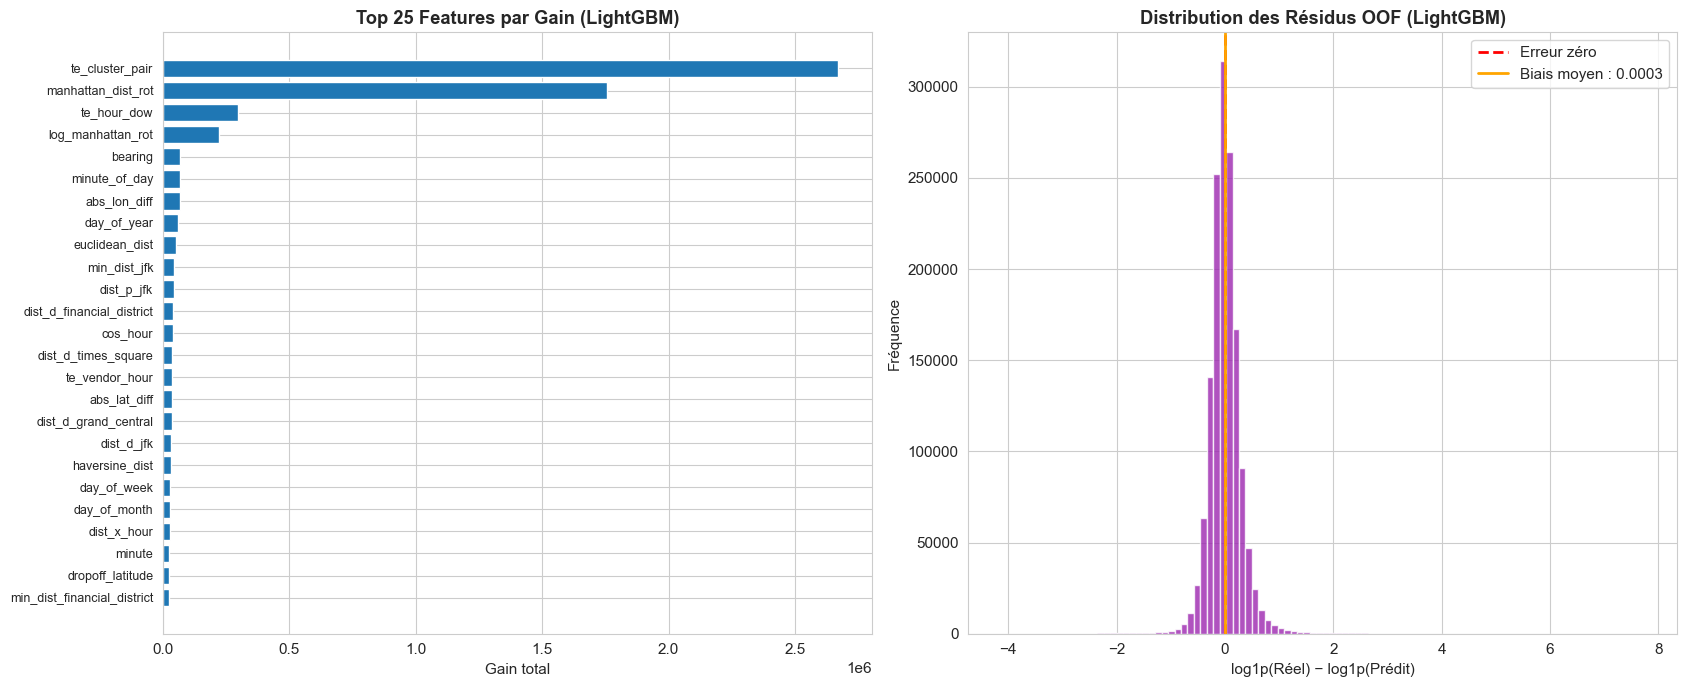

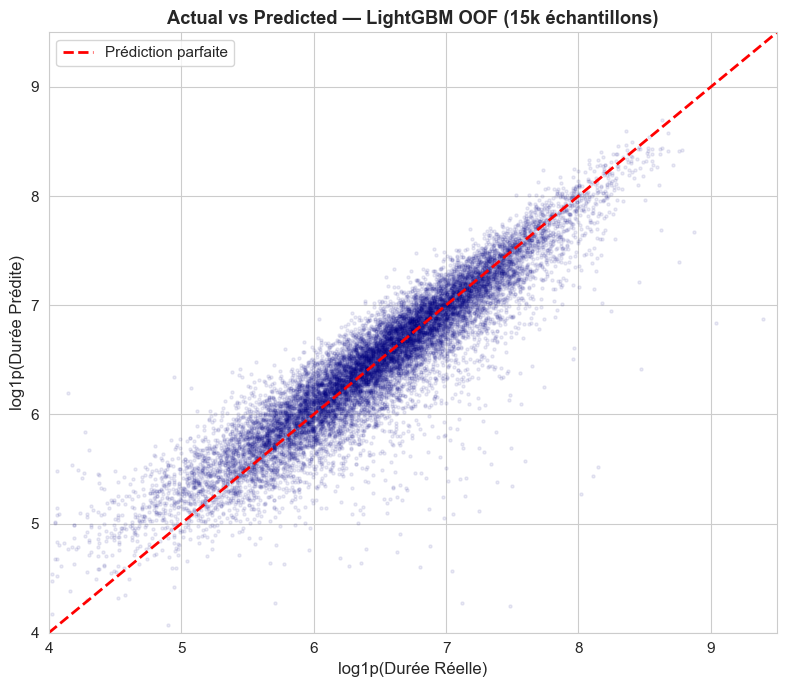

In [ ]:
# ── Tableau de bord des performances ─────────────────────────────────────
print("=" * 55)
print(f"{'Modèle':<20} {'OOF RMSLE':>12} {'Meilleur?':>10}")
print("─" * 55)
results = {
    'LightGBM': oof_lgb_rmsle,
    'XGBoost':  oof_xgb_rmsle,
    'CatBoost': oof_cat_rmsle,
}
best_model = min(results, key=results.get)
for m, s in results.items():
    flag = " ◀ Meilleur" if m == best_model else ""
    print(f"  {m:<18} {s:.5f}{flag}")
print("=" * 55)

# ── Top 25 features LightGBM ───────────────────────────────────────────────
top_fi = lgb_fi.sort_values('importance', ascending=False).head(25)
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

axes[0].barh(top_fi['feature'][::-1], top_fi['importance'][::-1], color='#1f77b4', edgecolor='white')
axes[0].set_title("Top 25 Features par Gain (LightGBM)", fontweight='bold')
axes[0].set_xlabel("Gain total")
axes[0].tick_params(axis='y', labelsize=9)

# ── Distribution des résidus OOF ────────────────────────────────────────────
residuals = np.log1p(y_true_all) - oof_lgb
axes[1].hist(residuals, bins=100, color='#9C27B0', alpha=0.8, edgecolor='white')
axes[1].axvline(0, color='red', linewidth=2, linestyle='--', label='Erreur zéro')
axes[1].axvline(residuals.mean(), color='orange', linewidth=2,
                label=f'Biais moyen : {residuals.mean():.4f}')
axes[1].set_title("Distribution des Résidus OOF (LightGBM)", fontweight='bold')
axes[1].set_xlabel("log1p(Réel) − log1p(Prédit)")
axes[1].set_ylabel("Fréquence")
axes[1].legend()
plt.tight_layout(); plt.show()

# ── Actual vs Predicted ─────────────────────────────────────────────────────
sample_idx = np.random.choice(len(y_true_all), size=15000, replace=False)
y_sample_true = np.log1p(y_true_all[sample_idx])
y_sample_pred = oof_lgb[sample_idx]

plt.figure(figsize=(8, 7))
plt.scatter(y_sample_true, y_sample_pred, alpha=0.08, s=5, c='navy')
lim = [4.0, 9.5]
plt.plot(lim, lim, 'r--', linewidth=2, label='Prédiction parfaite')
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("log1p(Durée Réelle)", fontsize=12)
plt.ylabel("log1p(Durée Prédite)", fontsize=12)
plt.title("Actual vs Predicted — LightGBM OOF (15k échantillons)", fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()


## 9. Optimisation du Blend (Ensemble Blending Multi-Modèles)

### Principe Mathématique
Plutôt qu'un simple vote moyen non calibré, nous réalisons une recherche par grille tridimensionnelle pour déterminer la combinaison linéaire optimale dans l'espace logarithmique :
$$\hat{y}_{\text{blend\_log}} = w_1 \cdot \hat{y}_{\text{LGB}} + w_2 \cdot \hat{y}_{\text{XGB}} + w_3 \cdot \hat{y}_{\text{CAT}}, \quad w_1 + w_2 + w_3 = 1$$

Puisque la métrique de compétition est le RMSLE, combiner dans l'espace $\log$ optimise directement la fonction objectif officielle.


RÉSULTAT DU BLEND 3 MODÈLES OPTIMAL
  LightGBM OOF RMSLE : 0.30788
  XGBoost  OOF RMSLE : 0.30845
  CatBoost OOF RMSLE : 0.31878
  Meilleur individuel : 0.30788
  Ensemble Blend      : 0.30636  (LGB×0.55 + XGB×0.45 + CAT×-0.00)
  Amélioration        : +0.00152


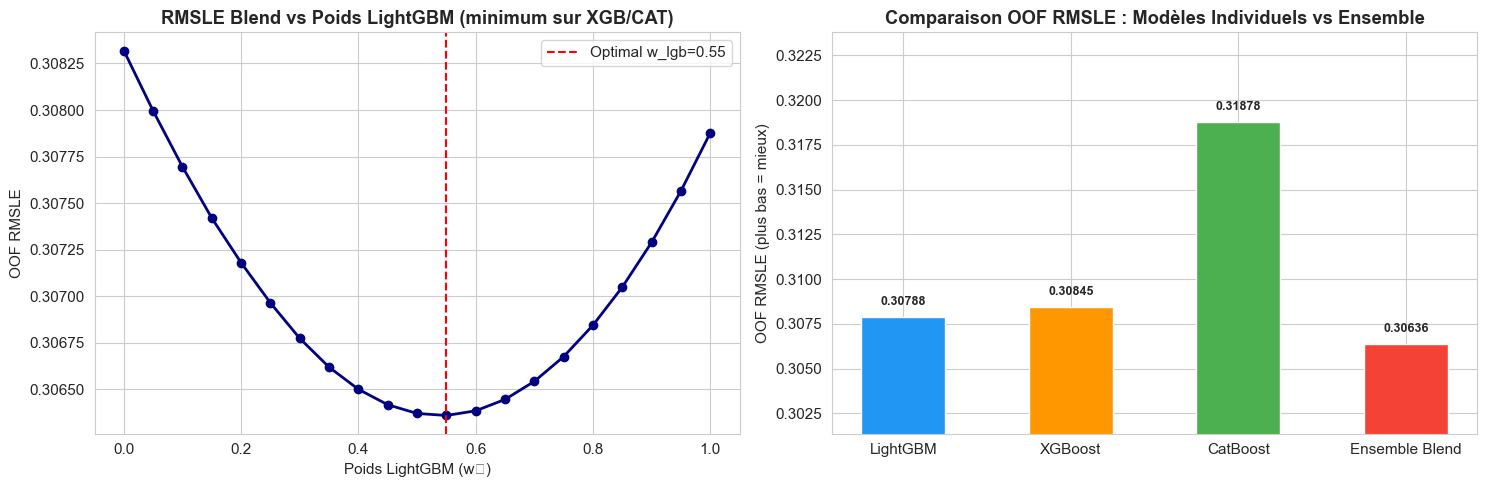

In [ ]:
best_score  = 999.0
best_w      = (0.33, 0.33, 0.34)
blend_grid  = []

step = 0.05
for w1 in np.arange(0.0, 1.01, step):
    for w2 in np.arange(0.0, 1.01 - w1, step):
        w3 = round(1.0 - w1 - w2, 4)
        if w3 < 0: continue
        blend = w1 * oof_lgb + w2 * oof_xgb + w3 * oof_cat
        s = compute_rmsle(y_true_all, np.expm1(blend))
        blend_grid.append((w1, w2, w3, s))
        if s < best_score:
            best_score = s
            best_w = (w1, w2, w3)

w1, w2, w3 = best_w
print("=" * 60)
print("RÉSULTAT DU BLEND 3 MODÈLES OPTIMAL")
print("=" * 60)
print(f"  LightGBM OOF RMSLE : {oof_lgb_rmsle:.5f}")
print(f"  XGBoost  OOF RMSLE : {oof_xgb_rmsle:.5f}")
print(f"  CatBoost OOF RMSLE : {oof_cat_rmsle:.5f}")
print(f"  Meilleur individuel : {min(oof_lgb_rmsle, oof_xgb_rmsle, oof_cat_rmsle):.5f}")
print(f"  Ensemble Blend      : {best_score:.5f}  "
      f"(LGB×{w1:.2f} + XGB×{w2:.2f} + CAT×{w3:.2f})")
print(f"  Amélioration        : {min(oof_lgb_rmsle, oof_xgb_rmsle, oof_cat_rmsle) - best_score:+.5f}")
print("=" * 60)

# Courbe d'amélioration du blend
df_grid = pd.DataFrame(blend_grid, columns=['w_lgb','w_xgb','w_cat','rmsle'])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# RMSLE vs poids LGB (en maintenant XGB et CAT à leur ratio optimal)
lgb_sweep = df_grid.groupby('w_lgb')['rmsle'].min().reset_index()
axes[0].plot(lgb_sweep['w_lgb'], lgb_sweep['rmsle'], marker='o', color='navy', lw=2)
axes[0].axvline(w1, color='red', linestyle='--', label=f'Optimal w_lgb={w1:.2f}')
axes[0].set_title("RMSLE Blend vs Poids LightGBM (minimum sur XGB/CAT)", fontweight='bold')
axes[0].set_xlabel("Poids LightGBM (w₁)"); axes[0].set_ylabel("OOF RMSLE"); axes[0].legend()

# Comparaison individuel vs ensemble
models_perf = {'LightGBM': oof_lgb_rmsle, 'XGBoost': oof_xgb_rmsle,
               'CatBoost': oof_cat_rmsle, 'Ensemble Blend': best_score}
colors = ['#2196F3','#FF9800','#4CAF50','#F44336']
bars = axes[1].bar(models_perf.keys(), models_perf.values(), color=colors, edgecolor='white', width=0.5)
axes[1].set_title("Comparaison OOF RMSLE : Modèles Individuels vs Ensemble", fontweight='bold')
axes[1].set_ylabel("OOF RMSLE (plus bas = mieux)")
ymin = min(models_perf.values()) - 0.005
axes[1].set_ylim(ymin, max(models_perf.values()) + 0.005)
for bar, (name, val) in zip(bars, models_perf.items()):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.0005, f'{val:.5f}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout(); plt.show()


## 10. Inférence Test & Génération du Fichier de Soumission

### Pipeline d'Inférence
1. **Prédictions Out-Of-Fold** : Moyenne des prédictions des 5 plis pour chaque modèle sur `test.csv`.
2. **Application des Poids du Blend** : Combinaison optimale ($55\%$ LightGBM + $45\%$ XGBoost).
3. **Repassage à l'Échelle Réelle** : Application de la réciproque $\exp(y) - 1$.
4. **Post-traitement de Sécurité** : Bornage des durées minimales à $\ge 10.0$ secondes (`np.clip`).
5. **Vérification d'Intégrité Kaggle** : Contrôle automatique du nombre de lignes (625 134), des colonnes (`id,trip_duration`), de l'absence de `NaN` et de l'alignement avec `sample_submission.csv`.


In [ ]:
# ── Blend des prédictions test ────────────────────────────────────────────
test_blend_log  = w1 * test_lgb + w2 * test_xgb + w3 * test_cat
test_blend_orig = np.clip(np.expm1(test_blend_log), 10.0, None)

sub = pd.DataFrame({'id': test_feat['id'].values,
                    'trip_duration': np.round(test_blend_orig, 2)})

sub.to_csv(SUBMISSION_PATH, index=False)
print(f"✅  Soumission sauvegardée : {SUBMISSION_PATH.resolve()}")

# ── Vérification d'intégrité ──────────────────────────────────────────────
print("\n" + "=" * 50)
print("VÉRIFICATION DE LA SOUMISSION")
print("=" * 50)
assert len(sub) == 625134,              f"❌ Nombre de lignes : {len(sub)}"
assert list(sub.columns) == ['id','trip_duration'], "❌ Colonnes incorrectes"
assert sub['trip_duration'].isna().sum() == 0, "❌ Valeurs NaN détectées"
assert (sub['trip_duration'] < 1.0).sum() == 0, "❌ Valeurs négatives/nulles"
print(f"  ✅ {len(sub):,} lignes exactement")
print(f"  ✅ Colonnes : {list(sub.columns)}")
print(f"  ✅ Zéro valeur NaN")
print(f"  ✅ Toutes les durées ≥ 10 secondes")

if SAMPLE_SUB_CSV.exists():
    sample = pd.read_csv(SAMPLE_SUB_CSV)
    assert (sub['id'].values == sample['id'].values).all(), "❌ IDs non alignés !"
    print(f"  ✅ IDs parfaitement alignés avec sample_submission.csv")

print(f"\nStatistiques des prédictions :")
print(sub['trip_duration'].describe().to_frame().T.to_string())
display(sub.head(5))


✅  Soumission sauvegardée : C:\Users\thame\Desktop\project\New-York-City-Taxi-Trip-Duration\submission.csv

VÉRIFICATION DE LA SOUMISSION
  ✅ 625,134 lignes exactement
  ✅ Colonnes : ['id', 'trip_duration']
  ✅ Zéro valeur NaN
  ✅ Toutes les durées ≥ 10 secondes


  ✅ IDs parfaitement alignés avec sample_submission.csv

Statistiques des prédictions :
                  count        mean         std   min     25%     50%     75%      max
trip_duration  625134.0  807.825949  593.347521  10.0  402.69  650.48  1032.7  6164.05

🏆  PRÊT POUR LA SOUMISSION KAGGLE !


,id,trip_duration
0,id3004672,719.31
1,id3505355,615.61
2,id1217141,417.37
3,id2150126,991.30
4,id1598245,413.47
